# 深度网络调参与评估
**课程：机器学习｜课堂实操 Notebook**

## 学习任务
1. 使用 Python 搭建多层神经网络，调整隐藏层结构与学习率并比较实验结果；
2. 根据训练集与测试集表现识别过拟合、欠拟合的可能迹象；
3. 使用正则化（L2）与 Dropout 思路改善泛化表现；
4. 使用准确率、精确率、召回率、F1 值等指标评估模型，并形成有依据的调优结论。

> 本 Notebook 采用 scikit-learn 自带的乳腺癌二分类数据集，数据可直接加载，无需额外下载。课堂中请先阅读 Markdown，再按顺序运行代码并记录观察。

## 一、实验环境与导入库
需要的主要库：`numpy`、`pandas`、`matplotlib`、`scikit-learn`、`tensorflow`（可选）。

本 Notebook 先使用 `scikit-learn` 的 `MLPClassifier` 完成神经网络调参，便于在普通教学电脑上运行；另提供可选的 Keras Dropout 示例。

In [ ]:
import warnings # 忽略警告
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer  # 加载乳腺癌数据集
from sklearn.model_selection import train_test_split  # 导入训练-测试分割函数
from sklearn.preprocessing import StandardScaler  # 导入标准化函数
from sklearn.pipeline import Pipeline  # 导入管道函数
from sklearn.neural_network import MLPClassifier  # 导入神经网络分类器
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)  # 导入评估指标函数 准确率 精确率 召回率 F1值
plt.rcParams['font.sans-serif'] = ['SimHei']  
# 解决负号 '-' 显示为方块的问题
plt.rcParams['axes.unicode_minus'] = False

RANDOM_STATE = 42 # 随机种子
print("NumPy:", np.__version__)
print("准备就绪")

NumPy: 2.5.3
准备就绪


## 二、加载并认识数据集
这是一个用于教学演示的二分类数据集。标签为 0/1，代表两个类别。真实项目中应结合数据来源理解类别含义，并检查样本分布与数据质量。

In [21]:
data = load_breast_cancer() # 加载乳腺癌数据集
X = pd.DataFrame(data.data, columns=data.feature_names) # 特征矩阵
y = pd.Series(data.target, name="target") # 目标变量

print("样本数：", X.shape[0])
print("特征数：", X.shape[1])
print("类别名称：", data.target_names)
display(X.head())
print("\n类别数量：")
display(y.value_counts().sort_index().rename(index={0: data.target_names[0], 1: data.target_names[1]}))

样本数： 569
特征数： 30
类别名称： ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



类别数量：


target
malignant    212
benign       357
Name: count, dtype: int64

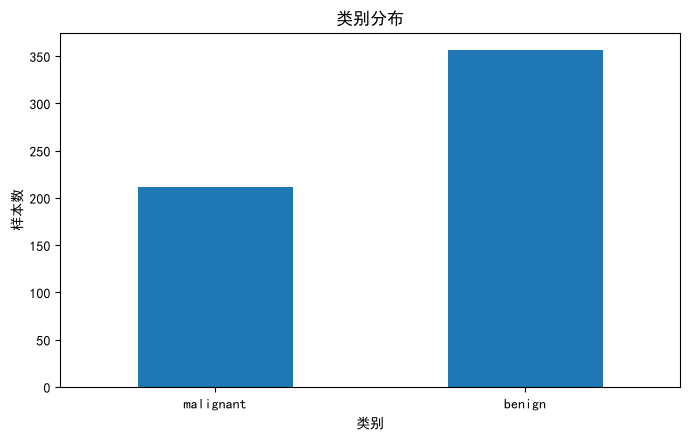

In [22]:
ax = y.value_counts().sort_index().plot(kind="bar", rot=0)  # 绘制类别分布柱状图
ax.set_xticks([0, 1], data.target_names)  # 设置x轴刻度标签
ax.set_title("类别分布") 
ax.set_xlabel("类别")
ax.set_ylabel("样本数")
plt.tight_layout()  # 自动调整子图参数，使子图之间的间距适当
plt.show()

## 三、划分训练集与测试集
- **训练集**：用于拟合模型参数。
- **测试集**：用于估计模型对未见样本的泛化表现。
- `stratify=y`：尽量保持训练集和测试集的类别比例一致。
- 标准化放在 `Pipeline` 中，避免先对全部数据拟合标准化器造成数据泄漏。

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
) # 划分训练集和测试集
print("训练集：", X_train.shape, "测试集：", X_test.shape)
print("训练集类别比例：")
display(y_train.value_counts(normalize=True).sort_index())  # 显示训练集类别比例

训练集： (426, 30) 测试集： (143, 30)
训练集类别比例：


target
0    0.373239
1    0.626761
Name: proportion, dtype: float64

## 四、建立基准模型
先训练一个包含两层隐藏层的多层感知机（MLP）。`hidden_layer_sizes=(64, 32)` 表示两层隐藏层分别有 64、32 个神经元；`learning_rate_init` 是初始学习率；`alpha` 是 L2 正则化强度。

In [24]:
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        alpha=0.0001,
        max_iter=800,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=25,
        random_state=RANDOM_STATE
    ))
]) # 定义神经网络管道  
baseline.fit(X_train, y_train) # 训练模型
print("训练完成，迭代轮数：", baseline.named_steps["mlp"].n_iter_)

训练完成，迭代轮数： 36


## 五、系统评估基准模型
准确率不一定能反映所有问题，因此同时观察精确率、召回率、F1 值和混淆矩阵。二分类任务中，指标还应结合具体业务中哪一类错误代价更高来解释。

,模型,训练准确率,测试准确率,测试精确率,测试召回率,测试F1
0,基准模型,0.946,0.9371,0.9451,0.9556,0.9503


              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        53
      benign       0.95      0.96      0.95        90

    accuracy                           0.94       143
   macro avg       0.93      0.93      0.93       143
weighted avg       0.94      0.94      0.94       143



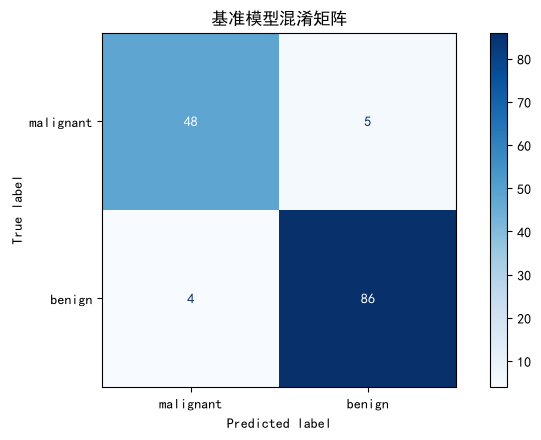

In [25]:
def evaluate_model(model, X_train, y_train, X_test, y_test, name="模型"):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    result = {
        "模型": name,
        "训练准确率": accuracy_score(y_train, train_pred),
        "测试准确率": accuracy_score(y_test, test_pred),
        "测试精确率": precision_score(y_test, test_pred, zero_division=0),
        "测试召回率": recall_score(y_test, test_pred, zero_division=0),
        "测试F1": f1_score(y_test, test_pred, zero_division=0)
    }
    return result

baseline_result = evaluate_model(baseline, X_train, y_train, X_test, y_test, "基准模型") # 评估基准模型
display(pd.DataFrame([baseline_result]).round(4)) # 显示基准模型评估结果
print(classification_report(y_test, baseline.predict(X_test), target_names=data.target_names, zero_division=0)) # 显示基准模型分类报告
ConfusionMatrixDisplay.from_predictions(
    y_test, baseline.predict(X_test), display_labels=data.target_names, cmap="Blues"
)
plt.title("基准模型混淆矩阵")
plt.tight_layout()
plt.show()

## 六、超参数对比实验：隐藏层结构
**实验问题：** 隐藏层更多、节点更多，模型是否一定更好？

请运行下面的实验，比较不同网络结构的训练与测试表现。为公平比较，各模型尽量使用相同的数据划分和随机种子。神经网络训练存在随机性，结果可能因软件版本而略有不同。

In [26]:
architectures = {
    "小网络 (16,)": (16,),
    "中网络 (64,)": (64,),
    "双隐藏层 (64, 32)": (64, 32),
    "较大网络 (128, 64)": (128, 64)
}
architecture_results = []

for name, layers in architectures.items():
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=layers,
            learning_rate_init=0.001,
            alpha=0.0001,
            max_iter=800,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=25,
            random_state=RANDOM_STATE
        ))
    ])
    model.fit(X_train, y_train)
    row = evaluate_model(model, X_train, y_train, X_test, y_test, name)
    row["隐藏层结构"] = str(layers)
    row["迭代轮数"] = model.named_steps["mlp"].n_iter_
    architecture_results.append(row)

architecture_df = pd.DataFrame(architecture_results)
display(architecture_df[["模型", "隐藏层结构", "训练准确率", "测试准确率", "测试精确率", "测试召回率", "测试F1", "迭代轮数"]].round(4))

,模型,隐藏层结构,训练准确率,测试准确率,测试精确率,测试召回率,测试F1,迭代轮数
0,"小网络 (16,)","(16,)",0.9366,0.9021,0.8800,0.9778,0.9263,59
1,"中网络 (64,)","(64,)",0.9484,0.9441,0.9556,0.9556,0.9556,43
2,"双隐藏层 (64, 32)","(64, 32)",0.9460,0.9371,0.9451,0.9556,0.9503,36
3,"较大网络 (128, 64)","(128, 64)",0.9695,0.9510,0.9462,0.9778,0.9617,39


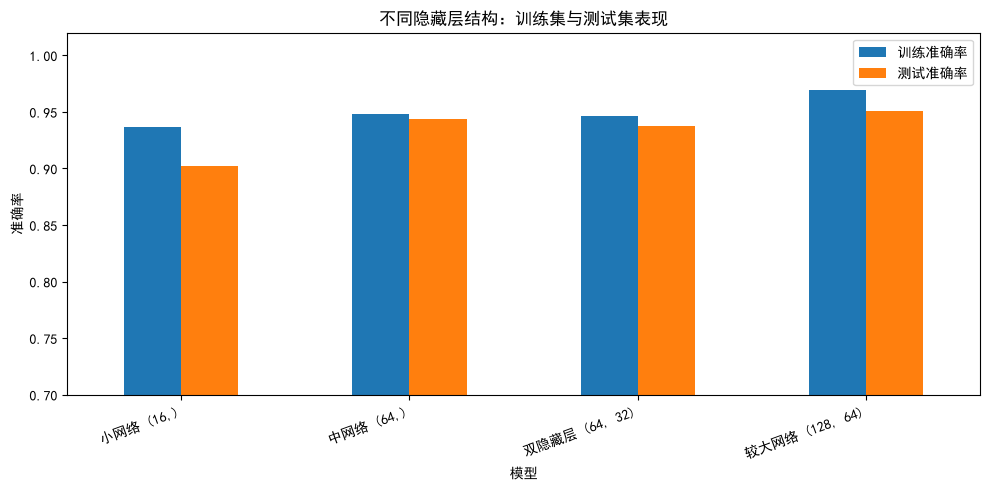

In [27]:
architecture_df.set_index("模型")[["训练准确率", "测试准确率"]].plot(kind="bar", figsize=(10, 5))
plt.ylim(0.7, 1.02)
plt.ylabel("准确率")
plt.title("不同隐藏层结构：训练集与测试集表现")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### 课堂思考 1
1. 哪种网络结构的测试集 F1 值最高？
2. 网络规模增大后，训练准确率和测试准确率是否同步提升？
3. 如果训练准确率很高、测试准确率明显较低，可能说明什么？

**记录结论：** 请在下方填写你观察到的结果。

In [31]:
# 学生填写：把下面的字符串替换成自己的实验结论
student_conclusion_architecture = "在此填写：不同网络结构的实验观察与结论"
print(student_conclusion_architecture)

在此填写：不同网络结构的实验观察与结论


## 七、超参数对比实验：学习率
学习率控制每次参数更新的步幅。学习率过大可能导致训练不稳定；过小可能使收敛变慢。请比较不同学习率下的模型表现与迭代轮数。

In [29]:
learning_rates = [0.0001, 0.001, 0.01]
lr_results = []

for lr in learning_rates:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            learning_rate_init=lr,
            alpha=0.0001,
            max_iter=800,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=25,
            random_state=RANDOM_STATE
        ))
    ])
    model.fit(X_train, y_train)
    row = evaluate_model(model, X_train, y_train, X_test, y_test, f"学习率={lr}")
    row["学习率"] = lr
    row["迭代轮数"] = model.named_steps["mlp"].n_iter_
    lr_results.append(row)

lr_df = pd.DataFrame(lr_results)
display(lr_df[["学习率", "训练准确率", "测试准确率", "测试精确率", "测试召回率", "测试F1", "迭代轮数"]].round(4))

,学习率,训练准确率,测试准确率,测试精确率,测试召回率,测试F1,迭代轮数
0,0.0001,0.8967,0.8322,0.8929,0.8333,0.8621,68
1,0.0010,0.9460,0.9371,0.9451,0.9556,0.9503,36
2,0.0100,0.9906,0.9790,0.9888,0.9778,0.9832,43


## 八、识别欠拟合与过拟合
一种初步判断方式是比较训练集和测试集表现：
- **欠拟合迹象**：训练集和测试集表现都较差，模型可能过于简单或训练不足。
- **过拟合迹象**：训练集表现明显好于测试集，模型可能学到了训练样本中的特定噪声。
- **注意**：仅凭一次划分不能下定论，还应检查数据量、类别分布、数据泄漏与交叉验证结果。

In [30]:
diagnosis_df = architecture_df[["模型", "训练准确率", "测试准确率"]].copy()
diagnosis_df["训练-测试差距"] = diagnosis_df["训练准确率"] - diagnosis_df["测试准确率"]
display(diagnosis_df.round(4))

,模型,训练准确率,测试准确率,训练-测试差距
0,"小网络 (16,)",0.9366,0.9021,0.0345
1,"中网络 (64,)",0.9484,0.9441,0.0043
2,"双隐藏层 (64, 32)",0.9460,0.9371,0.0089
3,"较大网络 (128, 64)",0.9695,0.9510,0.0184


## 九、正则化实验：比较 L2 强度
`alpha` 控制 L2 正则化强度。较大的 `alpha` 会更强地限制权重规模，但并非越大越好。请观察训练集与测试集表现是否发生变化。

In [12]:
alphas = [0.00001, 0.0001, 0.01, 0.1]
alpha_results = []

for alpha in alphas:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            learning_rate_init=0.001,
            alpha=alpha,
            max_iter=800,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=25,
            random_state=RANDOM_STATE
        ))
    ])
    model.fit(X_train, y_train)
    row = evaluate_model(model, X_train, y_train, X_test, y_test, f"alpha={alpha}")
    row["L2强度 alpha"] = alpha
    alpha_results.append(row)

alpha_df = pd.DataFrame(alpha_results)
display(alpha_df[["L2强度 alpha", "训练准确率", "测试准确率", "测试精确率", "测试召回率", "测试F1"]].round(4))

,L2强度 alpha,训练准确率,测试准确率,测试精确率,测试召回率,测试F1
0,0.0000,0.946,0.9371,0.9451,0.9556,0.9503
1,0.0001,0.946,0.9371,0.9451,0.9556,0.9503
2,0.0100,0.946,0.9371,0.9451,0.9556,0.9503
3,0.1000,0.946,0.9371,0.9451,0.9556,0.9503


## 十、早停策略与训练过程监控
`early_stopping=True` 会从训练数据中划出一部分作为验证集；当验证分数连续若干轮没有改善时提前停止训练。下面查看基准模型的损失曲线。

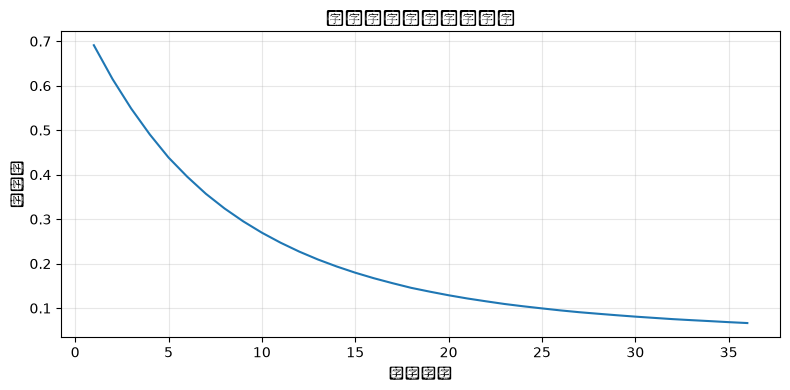

实际迭代轮数： 36
最后一次记录的损失值： 0.06641


In [13]:
loss_curve = baseline.named_steps["mlp"].loss_curve_
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(loss_curve) + 1), loss_curve)
plt.xlabel("迭代轮数")
plt.ylabel("损失值")
plt.title("基准模型训练损失曲线")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("实际迭代轮数：", len(loss_curve))
print("最后一次记录的损失值：", round(loss_curve[-1], 5))

## 十一、可选拓展：Keras 中使用 Dropout
本节需要安装 TensorFlow。若教学电脑未安装，可跳过；前面的核心实验不依赖 TensorFlow。

Dropout 在训练时随机屏蔽一部分神经元输出，以降低神经元之间的过度依赖。Dropout 比例需要通过实验选择。

TensorFlow 版本： 2.21.0
Keras 模型训练完成。
测试集评估： [0.08109359443187714, 0.9720279574394226]


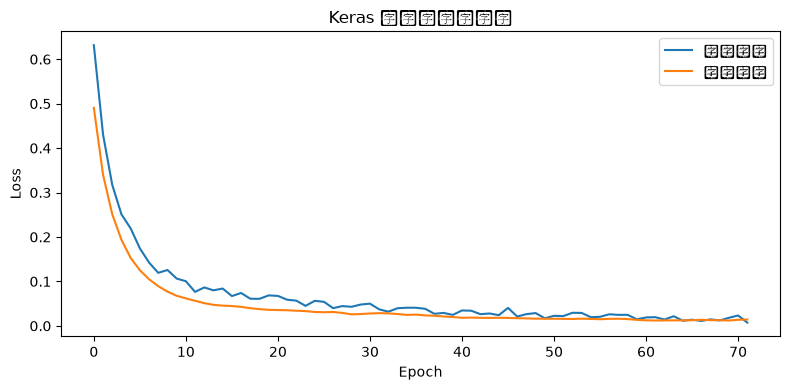

In [14]:
# 可选运行：如果尚未安装 TensorFlow，请先在终端执行 pip install tensorflow
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers

    print("TensorFlow 版本：", tf.__version__)

    X_train_np = X_train.to_numpy(dtype=np.float32)
    X_test_np = X_test.to_numpy(dtype=np.float32)
    y_train_np = y_train.to_numpy(dtype=np.float32)
    y_test_np = y_test.to_numpy(dtype=np.float32)

    # 使用训练集统计量标准化，避免测试集信息泄漏
    mean = X_train_np.mean(axis=0)
    std = X_train_np.std(axis=0)
    std[std == 0] = 1
    X_train_scaled = (X_train_np - mean) / std
    X_test_scaled = (X_test_np - mean) / std

    keras.utils.set_random_seed(RANDOM_STATE)
    keras_model = keras.Sequential([
        layers.Input(shape=(X_train_scaled.shape[1],)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid")
    ])
    keras_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    history = keras_model.fit(
        X_train_scaled, y_train_np,
        validation_split=0.15,
        epochs=100,
        batch_size=32,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=10, restore_best_weights=True
        )],
        verbose=0
    )
    print("Keras 模型训练完成。")
    print("测试集评估：", keras_model.evaluate(X_test_scaled, y_test_np, verbose=0))
    plt.figure(figsize=(8, 4))
    plt.plot(history.history["loss"], label="训练损失")
    plt.plot(history.history["val_loss"], label="验证损失")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Keras 训练与验证损失")
    plt.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    print("未检测到 TensorFlow，已跳过可选 Dropout 实验。")

## 十二、课堂综合任务
请以小组为单位完成以下任务，并在实验报告中记录数据和依据。

1. 从隐藏层结构、学习率、L2 强度中选择至少两个因素进行对比实验；
2. 至少记录训练准确率、测试准确率、测试精确率、测试召回率和测试 F1；
3. 结合训练—测试差距与损失曲线，分析是否存在过拟合或欠拟合迹象；
4. 给出一个最终模型配置，并说明选择理由；
5. 说明实验的局限性，例如单次数据划分、随机性或评价指标的适用范围。

### 实验报告模板
| 实验因素 | 参数设置 | 训练准确率 | 测试准确率 | 测试精确率 | 测试召回率 | 测试F1 | 观察与结论 |
|---|---|---:|---:|---:|---:|---:|---|
| 网络结构 |  |  |  |  |  |  |  |
| 学习率 |  |  |  |  |  |  |  |
| L2 强度 |  |  |  |  |  |  |  |

## 十三、课后练习
1. 将隐藏层结构改为 `(32,)`、`(128, 64, 32)`，比较测试集 F1；
2. 将 `early_stopping` 分别设置为 `True` 和 `False`，比较迭代轮数与泛化表现；
3. 解释为什么不能只根据训练准确率选择模型；
4. 写出 150—250 字的调优总结，必须引用本次实验中的至少两个具体数值作为依据。

## 本课知识回顾
- 超参数：隐藏层数、每层节点数、学习率、正则化强度等；
- 训练监控：损失曲线、验证集表现、早停；
- 过拟合/欠拟合：结合训练与测试表现进行初步判断；
- 模型评估：准确率、精确率、召回率、F1 值与混淆矩阵；
- 调优原则：控制变量、客观记录、基于测试与验证结果形成结论。